In [ ]:
import pandas as pd
import numpy as np
import kagglehub


np.random.seed(0)

/home/masila/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
nfl_data = pd.read_csv('NFL Play by Play 2009-2017 (v4).csv')

/tmp/ipykernel_38295/1925502549.py:1: DtypeWarning: Columns (25,51) have mixed types. Specify dtype option on import or set low_memory=False.
  nfl_data = pd.read_csv('NFL Play by Play 2009-2017 (v4).csv')


In [ ]:
nfl_data.head()

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,...,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2009-09-10,2009091000,1,1,NaN,15:00,15,3600.0,0.0,TEN,...,NaN,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,NaN,NaN,2009
1,2009-09-10,2009091000,1,1,1.0,14:53,15,3593.0,7.0,PIT,...,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009
2,2009-09-10,2009091000,1,1,2.0,14:16,15,3556.0,37.0,PIT,...,NaN,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,NaN,NaN,2009
3,2009-09-10,2009091000,1,1,3.0,13:35,14,3515.0,41.0,PIT,...,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009
4,2009-09-10,2009091000,1,1,4.0,13:27,14,3507.0,8.0,PIT,...,NaN,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,NaN,NaN,2009


In [ ]:
#missing values
nfl_data.isnull().sum()[0:10]

Date                0
GameID              0
Drive               0
qtr                 0
down            61154
time              224
TimeUnder           0
TimeSecs          224
PlayTimeDiff      444
SideofField       528
dtype: int64

In [ ]:
nfl_data.shape

(407688, 102)

In [ ]:
nfl_data.columns.value_counts().sum()

np.int64(102)

In [ ]:
nfl_data['down'].isnull().sum()

np.int64(61154)

In [ ]:
#getting the percentage of missing values
missing_values_count = nfl_data.isnull().sum().sum()
missing_values_count

np.int64(11505187)

In [ ]:
total_cells = np.prod(nfl_data.shape)
total_cells

np.int64(41584176)

In [ ]:
(missing_values_count/total_cells) * 100

np.float64(27.66722370547874)

In [ ]:
nfl_data.TimeSecs.head()

0    3600.0
1    3593.0
2    3556.0
3    3515.0
4    3507.0
Name: TimeSecs, dtype: float64

In [ ]:
nfl_data.dropna()

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,...,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season


In [ ]:
columns_with_na_dropped = nfl_data.dropna(axis=1)

In [ ]:
columns_with_na_dropped.head()

,Date,GameID,Drive,qtr,TimeUnder,ydstogo,ydsnet,PlayAttempted,Yards.Gained,sp,...,AwayTeam,Timeout_Indicator,posteam_timeouts_pre,HomeTimeouts_Remaining_Pre,AwayTimeouts_Remaining_Pre,HomeTimeouts_Remaining_Post,AwayTimeouts_Remaining_Post,ExPoint_Prob,TwoPoint_Prob,Season
0,2009-09-10,2009091000,1,1,15,0,0,1,39,0,...,TEN,0,3,3,3,3,3,0.0,0.0,2009
1,2009-09-10,2009091000,1,1,15,10,5,1,5,0,...,TEN,0,3,3,3,3,3,0.0,0.0,2009
2,2009-09-10,2009091000,1,1,15,5,2,1,-3,0,...,TEN,0,3,3,3,3,3,0.0,0.0,2009
3,2009-09-10,2009091000,1,1,14,8,2,1,0,0,...,TEN,0,3,3,3,3,3,0.0,0.0,2009
4,2009-09-10,2009091000,1,1,14,8,2,1,0,0,...,TEN,0,3,3,3,3,3,0.0,0.0,2009


In [ ]:
subset_nfl_data = nfl_data.loc[:, 'EPA':'Season'].head()
subset_nfl_data

,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2.014474,NaN,NaN,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,NaN,NaN,2009
1,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009
2,-1.402760,NaN,NaN,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,NaN,NaN,2009
3,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009
4,2.097796,NaN,NaN,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,NaN,NaN,2009


In [ ]:
subset_nfl_data.fillna(0)

,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2.014474,0.000000,0.000000,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,0.000000,0.000000,2009
1,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009
2,-1.402760,0.000000,0.000000,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,0.000000,0.000000,2009
3,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009
4,2.097796,0.000000,0.000000,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,0.000000,0.000000,2009


In [ ]:
#This fill every NaN with the value that comes directly after it, otherwise fill with 0.
subset_nfl_data.bfill(axis=0).fillna(0)

,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2.014474,-1.068169,1.146076,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,-0.032244,0.036899,2009
1,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009
2,-1.402760,3.318841,-5.031425,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,0.106663,-0.156239,2009
3,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009
4,2.097796,0.000000,0.000000,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,0.000000,0.000000,2009


In [ ]:
sf_permits = pd.read_csv('Building_Permits.csv')
sf_permits.head()

/tmp/ipykernel_38295/2878087487.py:1: DtypeWarning: Columns (22,32) have mixed types. Specify dtype option on import or set low_memory=False.
  sf_permits = pd.read_csv('Building_Permits.csv')


,Permit Number,Permit Type,Permit Type Definition,Permit Creation Date,Block,Lot,Street Number,Street Number Suffix,Street Name,Street Suffix,...,Existing Construction Type,Existing Construction Type Description,Proposed Construction Type,Proposed Construction Type Description,Site Permit,Supervisor District,Neighborhoods - Analysis Boundaries,Zipcode,Location,Record ID
0,201505065519,4,sign - erect,05/06/2015,0326,023,140,NaN,Ellis,St,...,3.0,constr type 3,NaN,NaN,NaN,3.0,Tenderloin,94102.0,"(37.785719256680785, -122.40852313194863)",1380611233945
1,201604195146,4,sign - erect,04/19/2016,0306,007,440,NaN,Geary,St,...,3.0,constr type 3,NaN,NaN,NaN,3.0,Tenderloin,94102.0,"(37.78733980600732, -122.41063199757738)",1420164406718
2,201605278609,3,additions alterations or repairs,05/27/2016,0595,203,1647,NaN,Pacific,Av,...,1.0,constr type 1,1.0,constr type 1,NaN,3.0,Russian Hill,94109.0,"(37.7946573324287, -122.42232562979227)",1424856504716
3,201611072166,8,otc alterations permit,11/07/2016,0156,011,1230,NaN,Pacific,Av,...,5.0,wood frame (5),5.0,wood frame (5),NaN,3.0,Nob Hill,94109.0,"(37.79595867909168, -122.41557405519474)",1443574295566
4,201611283529,6,demolitions,11/28/2016,0342,001,950,NaN,Market,St,...,3.0,constr type 3,NaN,NaN,NaN,6.0,Tenderloin,94102.0,"(37.78315261897309, -122.40950883997789)",144548169992


In [ ]:
sf_permits.shape

(198900, 43)

In [ ]:
sf_permits.isnull().sum()

Permit Number                                  0
Permit Type                                    0
Permit Type Definition                         0
Permit Creation Date                           0
Block                                          0
Lot                                            0
Street Number                                  0
Street Number Suffix                      196684
Street Name                                    0
Street Suffix                               2768
Unit                                      169421
Unit Suffix                               196939
Description                                  290
Current Status                                 0
Current Status Date                            0
Filed Date                                     0
Issued Date                                14940
Completed Date                            101709
First Construction Document Date           14946
Structural Notification                   191978
Number of Existing S

In [ ]:
sf_permits.dropna(axis=1)

,Permit Number,Permit Type,Permit Type Definition,Permit Creation Date,Block,Lot,Street Number,Street Name,Current Status,Current Status Date,Filed Date,Record ID
0,201505065519,4,sign - erect,05/06/2015,0326,023,140,Ellis,expired,12/21/2017,05/06/2015,1380611233945
1,201604195146,4,sign - erect,04/19/2016,0306,007,440,Geary,issued,08/03/2017,04/19/2016,1420164406718
2,201605278609,3,additions alterations or repairs,05/27/2016,0595,203,1647,Pacific,withdrawn,09/26/2017,05/27/2016,1424856504716
3,201611072166,8,otc alterations permit,11/07/2016,0156,011,1230,Pacific,complete,07/24/2017,11/07/2016,1443574295566
4,201611283529,6,demolitions,11/28/2016,0342,001,950,Market,issued,12/01/2017,11/28/2016,144548169992
...,...,...,...,...,...,...,...,...,...,...,...,...
198895,M862628,8,otc alterations permit,12/05/2017,0113,017A,1228,Montgomery,issued,12/05/2017,12/05/2017,1489337276729
198896,201712055595,8,otc alterations permit,12/05/2017,0271,014,580,Bush,issued,12/06/2017,12/05/2017,1489462354993
198897,M863507,8,otc alterations permit,12/06/2017,4318,019,1568,Indiana,issued,12/06/2017,12/06/2017,1489539379952
198898,M863747,8,otc alterations permit,12/06/2017,0298,029,795,Sutter,issued,12/06/2017,12/06/2017,1489608233656


In [ ]:
sf_permits.columns.value_counts().sum()

np.int64(43)

In [ ]:
pip install scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
pip install mlxtend

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from mlxtend.preprocessing import minmax_scaling

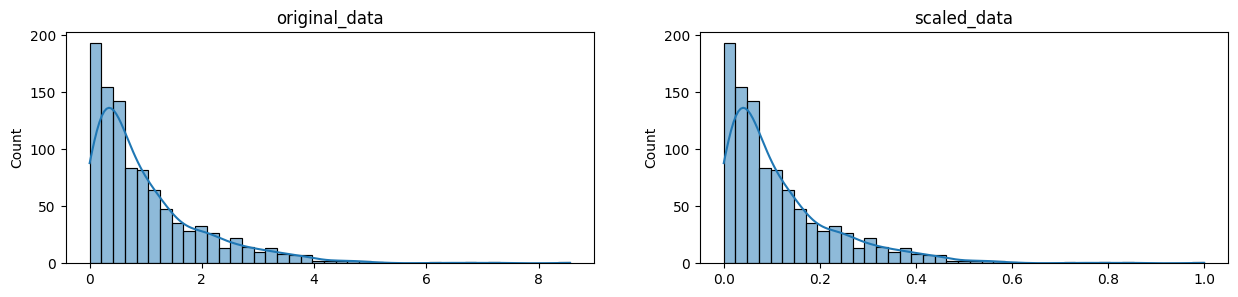

In [ ]:
original_data = np.random.exponential(size=1000)
scaled_data = minmax_scaling(original_data, columns=[0])


fig, ax = plt.subplots(1, 2, figsize=(15,3))
sns.histplot(original_data, ax=ax[0], kde=True, legend=False)
ax[0].set_title("original_data")
sns.histplot(scaled_data, ax=ax[1], kde=True, legend=False)
ax[1].set_title('scaled_data')
plt.show()

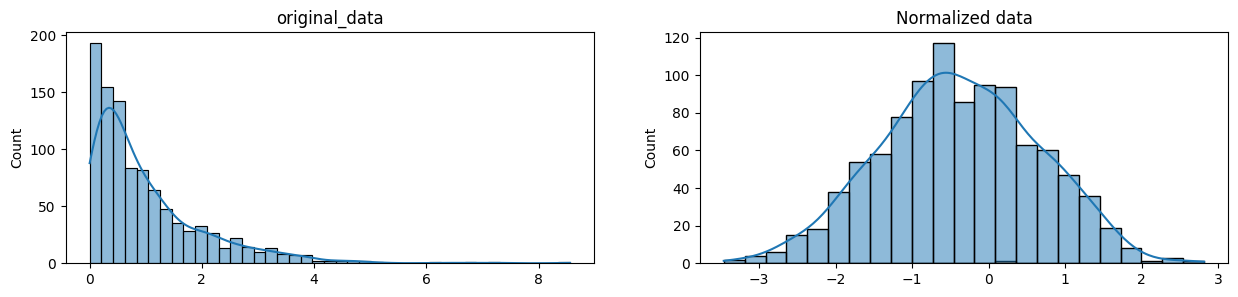

In [ ]:
normalized_data = stats.boxcox(original_data)
fig, ax  = plt.subplots(1,2, figsize=(15,3))
sns.histplot(original_data, ax=ax[0], kde=True, legend=False)
ax[0].set_title('original_data')
sns.histplot(normalized_data, ax=ax[1], kde=True, legend=False)
ax[1].set_title('Normalized data')
plt.show()

In [ ]:
kickstarters_2017 = pd.read_csv('ks-projects-201801.csv')
kickstarters_2017.columns

Index(['ID', 'name', 'category', 'main_category', 'currency', 'deadline',
       'goal', 'launched', 'pledged', 'state', 'backers', 'country',
       'usd pledged', 'usd_pledged_real', 'usd_goal_real'],
      dtype='object')

In [ ]:
original_data2 = pd.DataFrame(kickstarters_2017.usd_goal_real)
original_data2


,usd_goal_real
0,1533.95
1,30000.00
2,45000.00
3,5000.00
4,19500.00
...,...
378656,50000.00
378657,1500.00
378658,15000.00
378659,15000.00


In [ ]:
scaled_data2 = minmax_scaling(original_data2, columns=['usd_goal_real'])
print(f'Minimal Value {original_data2.min()} Maximum value is {original_data2.max()}')

Minimal Value usd_goal_real    0.01
dtype: float64 Maximum value is usd_goal_real    1.663614e+08
dtype: float64


In [ ]:
scaled_data2.head()

,usd_goal_real
0,0.000009
1,0.000180
2,0.000270
3,0.000030
4,0.000117


In [ ]:
print(f'Minimum value in scaled data {scaled_data2.min()} Maximum value in scaled data is {scaled_data2.max()}')

Minimum value in scaled data usd_goal_real    0.0
dtype: float64 Maximum value in scaled data is usd_goal_real    1.0
dtype: float64


In [ ]:
original_goal_data = pd.DataFrame(kickstarters_2017.goal)

In [ ]:
original_goal_data.head()

,goal
0,1000.0
1,30000.0
2,45000.0
3,5000.0
4,19500.0


In [ ]:
scaled_goal_data = minmax_scaling(original_goal_data, columns=['goal'])

In [ ]:
print(scaled_goal_data.min())
scaled_goal_data.max()

goal    0.0
dtype: float64


goal    1.0
dtype: float64

In [ ]:
#get the index of all positive pledges - boxcox doesn't take negative values
index_of_positive_pledges = kickstarters_2017.usd_pledged_real > 0
index_of_positive_pledges

0         False
1          True
2          True
3          True
4          True
          ...  
378656     True
378657     True
378658     True
378659     True
378660     True
Name: usd_pledged_real, Length: 378661, dtype: bool

In [ ]:
positive_pledges = kickstarters_2017.usd_pledged_real.loc[index_of_positive_pledges]
positive_pledges

1          2421.0
2           220.0
3             1.0
4          1283.0
5         52375.0
           ...   
378656       25.0
378657      155.0
378658       20.0
378659      200.0
378660      524.0
Name: usd_pledged_real, Length: 326134, dtype: float64

In [ ]:
normalized_pledges = pd.Series(stats.boxcox(positive_pledges)[0], 
                               name='usd_pledged_real', index=positive_pledges.index)


In [ ]:
print('Original data\nPreview:\n', positive_pledges.head())
print('Minimum value:', float(positive_pledges.min()),
      '\nMaximum value:', float(positive_pledges.max()))
print('_'*30)

print('\nNormalized data\nPreview:\n', normalized_pledges.head())
print('Minimum value:', float(normalized_pledges.min()),
      '\nMaximum value:', float(normalized_pledges.max()))

Original data
Preview:
 1     2421.0
2      220.0
3        1.0
4     1283.0
5    52375.0
Name: usd_pledged_real, dtype: float64
Minimum value: 0.45 
Maximum value: 20338986.27
______________________________

Normalized data
Preview:
 1    10.165142
2     6.468598
3     0.000000
4     9.129277
5    15.836852
Name: usd_pledged_real, dtype: float64
Minimum value: -0.7779954154530838 
Maximum value: 30.690537060647134


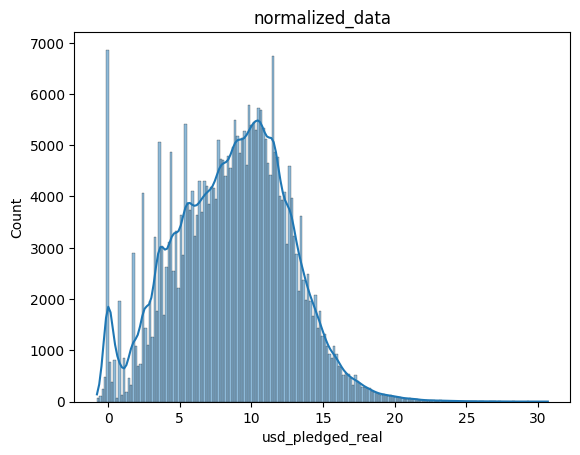

In [ ]:
ax = sns.histplot(normalized_pledges, kde=True)
ax.set_title("normalized_data")
plt.show()

In [ ]:
index_of_positive_pledges2 = kickstarters_2017.pledged > 0
positive_pledges2 = kickstarters_2017.pledged.loc[index_of_positive_pledges2]
normalized_pledges2 =pd.Series(stats.boxcox(positive_pledges2)[0], name="usd_pledged", index=positive_pledges2.index)

In [ ]:
normalized_pledges2

1         10.013887
2          6.403368
3          0.000000
4          9.005193
5         15.499596
            ...    
378656     3.562025
378657     5.919593
378658     3.291544
378659     6.270664
378660     7.648440
Name: usd_pledged, Length: 326134, dtype: float64

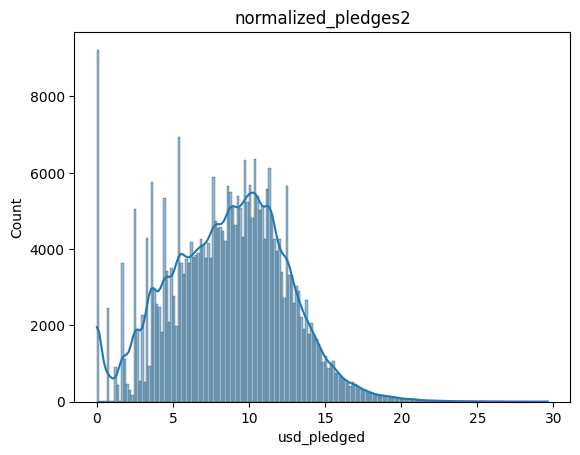

In [ ]:
ax = sns.histplot(normalized_pledges2, kde=True)
ax.set_title('normalized_pledges2')
plt.show()

In [ ]:
landslides = pd.read_csv('catalog.csv')

In [ ]:
landslides.head()

,id,date,time,continent_code,country_name,country_code,state/province,population,city/town,distance,...,geolocation,hazard_type,landslide_type,landslide_size,trigger,storm_name,injuries,fatalities,source_name,source_link
0,34,3/2/07,Night,NaN,United States,US,Virginia,16000,Cherry Hill,3.40765,...,"(38.600900000000003, -77.268199999999993)",Landslide,Landslide,Small,Rain,NaN,NaN,NaN,NBC 4 news,http://www.nbc4.com/news/11186871/detail.html
1,42,3/22/07,NaN,NaN,United States,US,Ohio,17288,New Philadelphia,3.33522,...,"(40.517499999999998, -81.430499999999995)",Landslide,Landslide,Small,Rain,NaN,NaN,NaN,Canton Rep.com,http://www.cantonrep.com/index.php?ID=345054&C...
2,56,4/6/07,NaN,NaN,United States,US,Pennsylvania,15930,Wilkinsburg,2.91977,...,"(40.4377, -79.915999999999997)",Landslide,Landslide,Small,Rain,NaN,NaN,NaN,The Pittsburgh Channel.com,https://web.archive.org/web/20080423132842/htt...
3,59,4/14/07,NaN,NaN,Canada,CA,Quebec,42786,Châteauguay,2.98682,...,"(45.322600000000001, -73.777100000000004)",Landslide,Riverbank collapse,Small,Rain,NaN,NaN,NaN,Le Soleil,http://www.hebdos.net/lsc/edition162007/articl...
4,61,4/15/07,NaN,NaN,United States,US,Kentucky,6903,Pikeville,5.66542,...,"(37.432499999999997, -82.493099999999998)",Landslide,Landslide,Small,Downpour,NaN,NaN,0.0,Matthew Crawford (KGS),NaN


In [ ]:
affected_population = pd.DataFrame(landslides.population)

In [ ]:
affected_population

,population
0,16000
1,17288
2,15930
3,42786
4,6903
...,...
1688,1646
1689,51400
1690,2406
1691,1048


In [ ]:
scaled_population = minmax_scaling(affected_population, columns=['population'])

In [ ]:
scaled_population

,population
0,0.001301
1,0.001406
2,0.001296
3,0.003480
4,0.000561
...,...
1688,0.000134
1689,0.004181
1690,0.000196
1691,0.000085


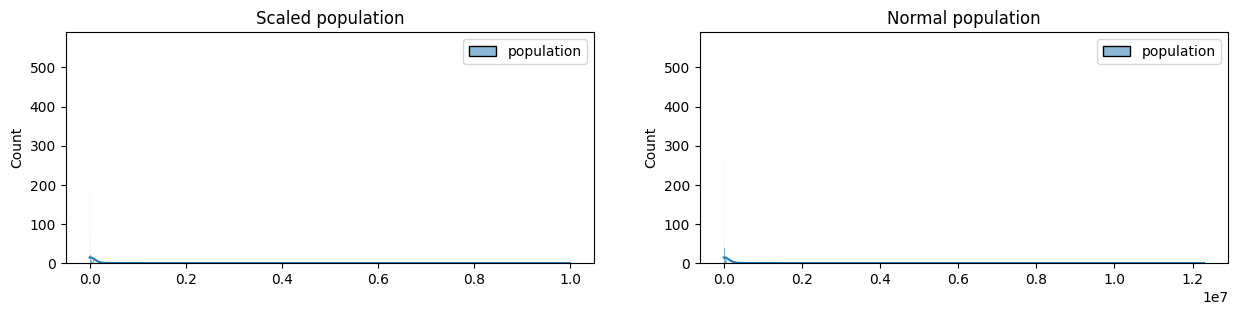

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(15,3))
sns.histplot(scaled_population, kde=True, ax=ax[0])
ax[0].set_title("Scaled population")
sns.histplot(affected_population, ax=ax[1], kde=True)
ax[1].set_title("Normal population")
plt.show()

In [ ]:
index_of_positive_population = landslides.population > 0
positive_population = landslides.population.loc[index_of_positive_population]
positive_population

0       16000
1       17288
2       15930
3       42786
4        6903
        ...  
1688     1646
1689    51400
1690     2406
1691     1048
1692     2066
Name: population, Length: 1654, dtype: int64

In [ ]:
normalized_population = pd.Series(stats.boxcox(positive_population)[0], name="affected_population", index=positive_population.index)

In [ ]:
normalized_population

0       3.855432
1       3.863561
2       3.854967
3       3.948613
4       3.757096
          ...   
1688    3.538135
1689    3.963758
1690    3.603373
1691    3.452691
1692    3.577879
Name: affected_population, Length: 1654, dtype: float64

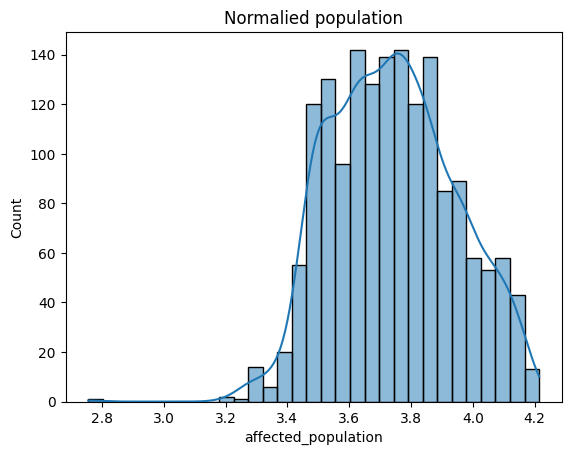

In [ ]:
ax = sns.histplot(normalized_population, kde=True)
ax.set_title("Normalied population")
plt.show()

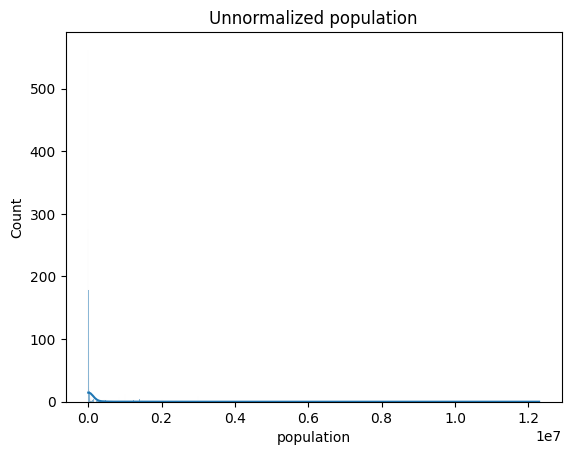

In [ ]:
ax=sns.histplot(landslides.population, kde=True)
ax.set_title("Unnormalized population")
plt.show()

In [ ]:
landslides.head()

,id,date,time,continent_code,country_name,country_code,state/province,population,city/town,distance,...,geolocation,hazard_type,landslide_type,landslide_size,trigger,storm_name,injuries,fatalities,source_name,source_link
0,34,3/2/07,Night,NaN,United States,US,Virginia,16000,Cherry Hill,3.40765,...,"(38.600900000000003, -77.268199999999993)",Landslide,Landslide,Small,Rain,NaN,NaN,NaN,NBC 4 news,http://www.nbc4.com/news/11186871/detail.html
1,42,3/22/07,NaN,NaN,United States,US,Ohio,17288,New Philadelphia,3.33522,...,"(40.517499999999998, -81.430499999999995)",Landslide,Landslide,Small,Rain,NaN,NaN,NaN,Canton Rep.com,http://www.cantonrep.com/index.php?ID=345054&C...
2,56,4/6/07,NaN,NaN,United States,US,Pennsylvania,15930,Wilkinsburg,2.91977,...,"(40.4377, -79.915999999999997)",Landslide,Landslide,Small,Rain,NaN,NaN,NaN,The Pittsburgh Channel.com,https://web.archive.org/web/20080423132842/htt...
3,59,4/14/07,NaN,NaN,Canada,CA,Quebec,42786,Châteauguay,2.98682,...,"(45.322600000000001, -73.777100000000004)",Landslide,Riverbank collapse,Small,Rain,NaN,NaN,NaN,Le Soleil,http://www.hebdos.net/lsc/edition162007/articl...
4,61,4/15/07,NaN,NaN,United States,US,Kentucky,6903,Pikeville,5.66542,...,"(37.432499999999997, -82.493099999999998)",Landslide,Landslide,Small,Downpour,NaN,NaN,0.0,Matthew Crawford (KGS),NaN


In [ ]:
landslides.date.head()

0     3/2/07
1    3/22/07
2     4/6/07
3    4/14/07
4    4/15/07
Name: date, dtype: object

In [ ]:
landslides['date'] = pd.to_datetime(landslides.date, format='%m/%d/%y')

In [ ]:
landslides.date.dtype

dtype('<M8[ns]')

In [ ]:
landslides.date

0      2007-03-02
1      2007-03-22
2      2007-04-06
3      2007-04-14
4      2007-04-15
          ...    
1688   2015-12-07
1689   2016-02-22
1690   2016-02-23
1691   2016-02-26
1692   2016-03-02
Name: date, Length: 1693, dtype: datetime64[ns]

In [ ]:
#selecting day of month
day_of_month_landslides = landslides['date'].dt.day
day_of_month_landslides.head()

0     2.0
1    22.0
2     6.0
3    14.0
4    15.0
Name: date, dtype: float64

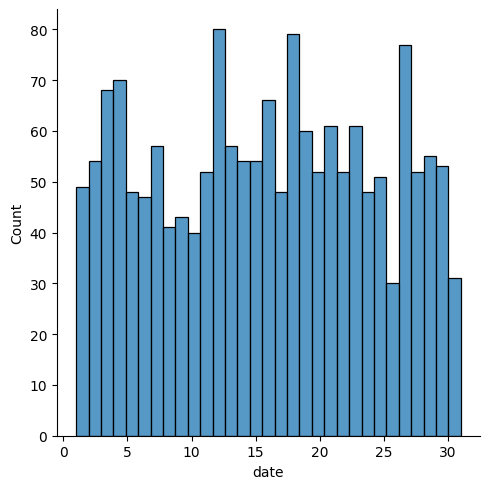

In [ ]:
day_of_month_landslides = day_of_month_landslides.dropna()

sns.displot(day_of_month_landslides, bins=31, kde=False)

In [ ]:
earthquakes = pd.read_csv('database.csv')

In [ ]:
earthquakes.columns

Index(['Date', 'Time', 'Latitude', 'Longitude', 'Type', 'Depth', 'Depth Error',
       'Depth Seismic Stations', 'Magnitude', 'Magnitude Type',
       'Magnitude Error', 'Magnitude Seismic Stations', 'Azimuthal Gap',
       'Horizontal Distance', 'Horizontal Error', 'Root Mean Square', 'ID',
       'Source', 'Location Source', 'Magnitude Source', 'Status'],
      dtype='object')

In [ ]:
earthquakes.Date.dtype

dtype('O')

In [ ]:
date_lengths = earthquakes.Date.str.len()
date_lengths.value_counts()

Date
10    23409
24        3
Name: count, dtype: int64

In [ ]:
indices = np.where([date_lengths == 24 ])[1]
print(f'Indices with corrupted data are {indices}')
earthquakes.loc[indices]

Indices with corrupted data are [ 3378  7512 20650]


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
3378,1975-02-23T02:58:41.000Z,1975-02-23T02:58:41.000Z,8.017,124.075,Earthquake,623.0,NaN,NaN,5.6,MB,...,NaN,NaN,NaN,NaN,NaN,USP0000A09,US,US,US,Reviewed
7512,1985-04-28T02:53:41.530Z,1985-04-28T02:53:41.530Z,-32.998,-71.766,Earthquake,33.0,NaN,NaN,5.6,MW,...,NaN,NaN,NaN,NaN,1.30,USP0002E81,US,US,HRV,Reviewed
20650,2011-03-13T02:23:34.520Z,2011-03-13T02:23:34.520Z,36.344,142.344,Earthquake,10.1,13.9,289.0,5.8,MWC,...,NaN,32.3,NaN,NaN,1.06,USP000HWQP,US,US,GCMT,Reviewed


In [ ]:
earthquakes.loc[3378, "Date"] = "02/23/1975"
earthquakes.loc[7512, "Date"] = "04/28/1985"
earthquakes.loc[20650, "Date"] = "03/13/2011"

earthquakes.Date = pd.to_datetime(earthquakes.Date, format="%m/%d/%Y")

In [ ]:
earthquakes.Date

0       1965-01-02
1       1965-01-04
2       1965-01-05
3       1965-01-08
4       1965-01-09
           ...    
23407   2016-12-28
23408   2016-12-28
23409   2016-12-28
23410   2016-12-29
23411   2016-12-30
Name: Date, Length: 23412, dtype: datetime64[ns]

In [ ]:
earthquakes['Date'].dt.month

0         1
1         1
2         1
3         1
4         1
         ..
23407    12
23408    12
23409    12
23410    12
23411    12
Name: Date, Length: 23412, dtype: int32

In [ ]:
day_of_month_wth_earthquakes = earthquakes.Date.dt.day

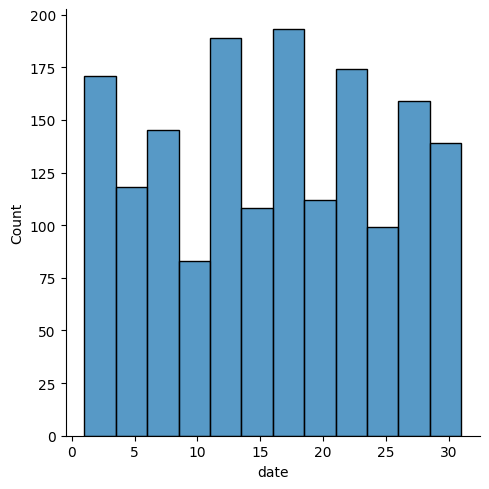

In [ ]:
sns.displot(day_of_month_landslides)

In [ ]:
#character encoding
import charset_normalizer

In [ ]:
before = "This is the euro symbol: €"
type(before)

str

In [ ]:
after = before.encode("utf-8", errors='replace')
type(after)

bytes

In [ ]:
after

b'This is the euro symbol: \xe2\x82\xac'

In [ ]:
print(after.decode("utf-8"))

This is the euro symbol: €


In [ ]:
kickstarter2016 = pd.read_csv('ks-projects-201612.csv')

UnicodeDecodeError: 'utf-8' codec can't decode byte 0x99 in position 7955: invalid start byte

In [ ]:
with open('ks-projects-201612.csv', 'rb') as rawdata:
    result = charset_normalizer.detect(rawdata.read())



print(result)

{'encoding': 'iso8859_10', 'language': 'English', 'confidence': 0.9968}


In [ ]:
pd.read_csv('ks-projects-201612.csv', encoding='iso8859_10').head()

/tmp/ipykernel_3775/2319109059.py:1: DtypeWarning: Columns (13,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  pd.read_csv('ks-projects-201612.csv', encoding='iso8859_10').head()


,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0,NaN,NaN,NaN,NaN
1,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220,NaN,NaN,NaN,NaN
2,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1,NaN,NaN,NaN,NaN
3,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283,NaN,NaN,NaN,NaN
4,1000014025,Monarch Espresso Bar,Restaurants,Food,USD,2016-04-01 13:38:27,50000,2016-02-26 13:38:27,52375,successful,224,US,52375,NaN,NaN,NaN,NaN


In [ ]:
pip install fuzzywuzzy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install python-Levenshtein

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 3.6 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [python-Levenshtein]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import fuzzywuzzy
from fuzzywuzzy import process

professors = pd.read_csv('pakistan_intellectual_capital.csv')

In [ ]:
professors.head()

,Unnamed: 0,S#,Teacher Name,University Currently Teaching,Department,Province University Located,Designation,Terminal Degree,Graduated from,Country,Year,Area of Specialization/Research Interests,Other Information
0,2,3,Dr. Abdul Basit,University of Balochistan,Computer Science & IT,Balochistan,Assistant Professor,PhD,Asian Institute of Technology,Thailand,NaN,Software Engineering & DBMS,NaN
1,4,5,Dr. Waheed Noor,University of Balochistan,Computer Science & IT,Balochistan,Assistant Professor,PhD,Asian Institute of Technology,Thailand,NaN,DBMS,NaN
2,5,6,Dr. Junaid Baber,University of Balochistan,Computer Science & IT,Balochistan,Assistant Professor,PhD,Asian Institute of Technology,Thailand,NaN,"Information processing, Multimedia mining",NaN
3,6,7,Dr. Maheen Bakhtyar,University of Balochistan,Computer Science & IT,Balochistan,Assistant Professor,PhD,Asian Institute of Technology,Thailand,NaN,"NLP, Information Retrieval, Question Answering...",NaN
4,24,25,Samina Azim,Sardar Bahadur Khan Women's University,Computer Science,Balochistan,Lecturer,BS,Balochistan University of Information Technolo...,Pakistan,2005.0,VLSI Electronics DLD Database,NaN


In [ ]:
professors.describe()

,Unnamed: 0,S#,Year
count,1142.000000,1142.000000,489.000000
mean,1054.350263,1055.350263,2010.456033
std,520.202783,520.202783,5.577565
min,2.000000,3.000000,1983.000000
25%,689.250000,690.250000,2008.000000
50%,1087.500000,1088.500000,2012.000000
75%,1476.750000,1477.750000,2014.000000
max,1980.000000,1981.000000,2018.000000


In [ ]:
professors.shape

(1142, 13)

In [ ]:
professors.columns

Index(['Unnamed: 0', 'S#', 'Teacher Name', 'University Currently Teaching',
       'Department', 'Province University Located', 'Designation',
       'Terminal Degree', 'Graduated from', 'Country', 'Year',
       'Area of Specialization/Research Interests', 'Other Information'],
      dtype='object')

In [ ]:
# get all the unique values in the 'Country' column
countries = professors['Country'].unique()

# sort them alphabetically and then take a closer look
print(countries.sort())
countries

None


array([' Germany', ' New Zealand', ' Sweden', ' USA', 'Australia',
       'Austria', 'Canada', 'China', 'Finland', 'France', 'Greece',
       'HongKong', 'Ireland', 'Italy', 'Japan', 'Macau', 'Malaysia',
       'Mauritius', 'Netherland', 'New Zealand', 'Norway', 'Pakistan',
       'Portugal', 'Russian Federation', 'Saudi Arabia', 'Scotland',
       'Singapore', 'South Korea', 'SouthKorea', 'Spain', 'Sweden',
       'Thailand', 'Turkey', 'UK', 'USA', 'USofA', 'Urbana', 'germany'],
      dtype=object)

In [ ]:
professors.Country = professors.Country.str.lower()
professors.Country = professors.Country.str.strip()

In [ ]:
professors.Country.unique()

array(['thailand', 'pakistan', 'germany', 'austria', 'australia', 'uk',
       'china', 'france', 'usofa', 'southkorea', 'malaysia', 'sweden',
       'italy', 'canada', 'norway', 'ireland', 'new zealand', 'urbana',
       'portugal', 'russian federation', 'usa', 'finland', 'netherland',
       'greece', 'turkey', 'south korea', 'macau', 'singapore', 'spain',
       'japan', 'hongkong', 'saudi arabia', 'mauritius', 'scotland'],
      dtype=object)

In [ ]:
countries = professors.Country.unique()
countries.sort()
countries

array(['australia', 'austria', 'canada', 'china', 'finland', 'france',
       'germany', 'greece', 'hongkong', 'ireland', 'italy', 'japan',
       'macau', 'malaysia', 'mauritius', 'netherland', 'new zealand',
       'norway', 'pakistan', 'portugal', 'russian federation',
       'saudi arabia', 'scotland', 'singapore', 'south korea',
       'southkorea', 'spain', 'sweden', 'thailand', 'turkey', 'uk',
       'urbana', 'usa', 'usofa'], dtype=object)

In [ ]:
matches = fuzzywuzzy.process.extract("south korea", countries, limit=10, scorer=fuzzywuzzy.fuzz.token_sort_ratio)

matches



[('south korea', 100),
 ('saudi arabia', 43),
 ('norway', 35),
 ('ireland', 33),
 ('portugal', 32),
 ('singapore', 30),
 ('netherland', 29),
 ('macau', 25),
 ('usofa', 25),
 ('france', 24)]

In [ ]:
close_matches = [matches[0] for matches in matches if matches[1] >= 47]
close_matches

['south korea']

In [ ]:
rows_with_matches = professors.Country.isin(close_matches)
professors.Country.loc[rows_with_matches]

33      south korea
163     south korea
169     south korea
177     south korea
189     south korea
244     south korea
321     south korea
489     south korea
677     south korea
685     south korea
764     south korea
906     south korea
931     south korea
1137    south korea
1141    south korea
Name: Country, dtype: object

In [ ]:
def replace_matches_in_column(df, column, string_to_match, min_ratio = 47):
    # get a list of unique strings
    strings = df[column].unique()
    
    # get the top 10 closest matches to our input string
    matches = fuzzywuzzy.process.extract(string_to_match, strings, 
                                         limit=10, scorer=fuzzywuzzy.fuzz.token_sort_ratio)

    # only get matches with a ratio > 90
    close_matches = [matches[0] for matches in matches if matches[1] >= min_ratio]

    # get the rows of all the close matches in our dataframe
    rows_with_matches = df[column].isin(close_matches)

    # replace all rows with close matches with the input matches 
    df.loc[rows_with_matches, column] = string_to_match
    
    # let us know the function's done
    print("All done!")

In [ ]:
replace_matches_in_column(df=professors, column='Country', string_to_match="south korea")

All done!


In [ ]:
# get all the unique values in the 'Country' column
countries = professors['Country'].unique()

# sort them alphabetically and then take a closer look
countries.sort()
countries

array(['australia', 'austria', 'canada', 'china', 'finland', 'france',
       'germany', 'greece', 'hongkong', 'ireland', 'italy', 'japan',
       'macau', 'malaysia', 'mauritius', 'netherland', 'new zealand',
       'norway', 'pakistan', 'portugal', 'russian federation',
       'saudi arabia', 'scotland', 'singapore', 'south korea', 'spain',
       'sweden', 'thailand', 'turkey', 'uk', 'urbana', 'usa', 'usofa'],
      dtype=object)